=== BẮT ĐẦU XỬ LÝ ĐỒ THỊ TRI THỨC CHO HƯỚNG 2 ===

--- 5 dòng đầu tiên của tập Triples ---
                 head    relation              tail
0  Product_B00005NDAB   HAS_BRAND  Brand_Maybelline
1  Product_B00005NDAB  BELONGS_TO        Cat_Beauty
2  Product_B00005NDAB  BELONGS_TO        Cat_Makeup
3  Product_B00005NDAB  BELONGS_TO          Cat_Lips
4  Product_B00005NDAC   HAS_BRAND     Brand_L'Oreal

Đồ thị đã tạo thành công với 12 nút và 15 cạnh quan hệ.


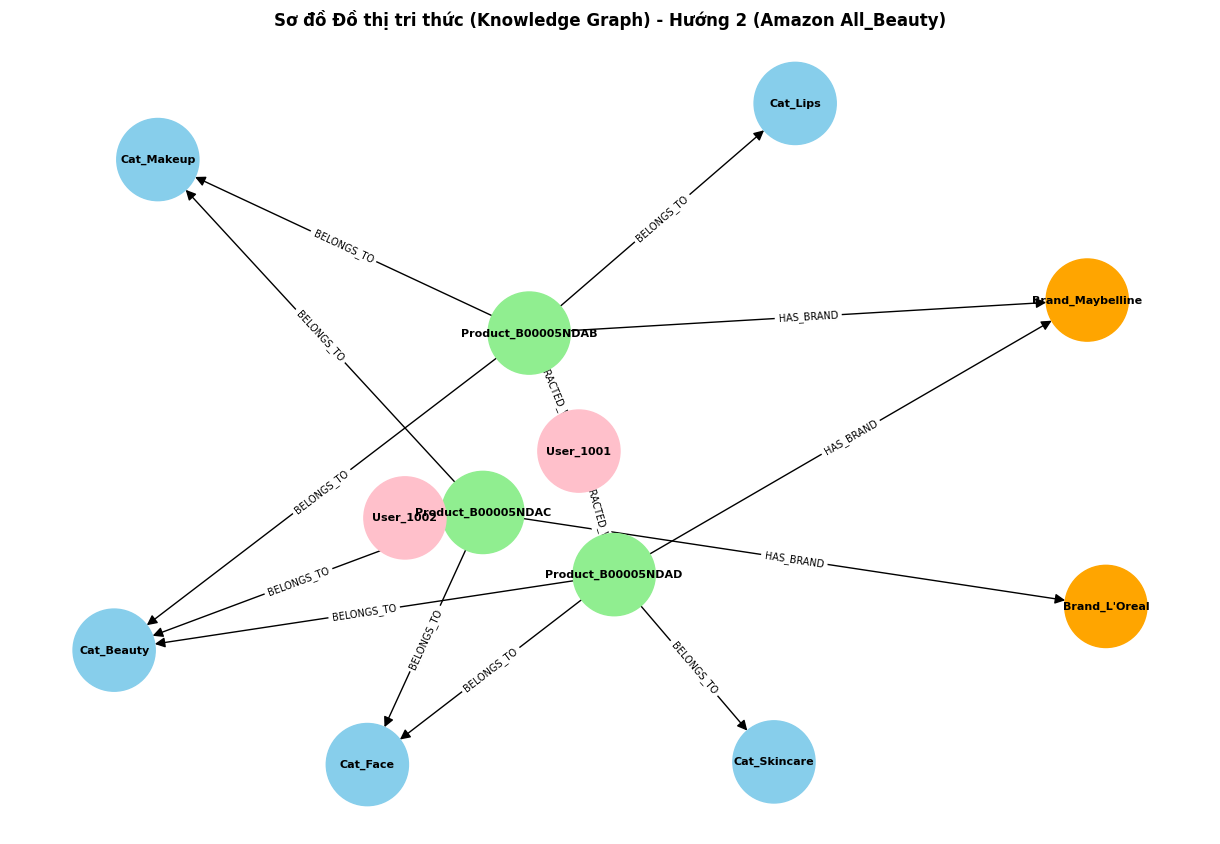

In [ ]:
# -*- coding: utf-8 -*-
"""Direction2_KnowledgeGraph.ipynb

Automatically generated by Colab.

# HƯỚNG 2: GỢI Ý SẢN PHẨM TÍCH HỢP ĐỒ THỊ TRI THỨC (KNOWLEDGE GRAPH)
"""

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

print("=== BẮT ĐẦU XỬ LÝ ĐỒ THỊ TRI THỨC CHO HƯỚNG 2 ===")

# 1. Đọc dữ liệu mẫu các bộ ba tri thức (Triples) đã trích xuất từ file Meta
# (Bạn có thể thay thế bằng cách đọc file kg_triples.csv thực tế)
data = [
    {"head": "Product_B00005NDAB", "relation": "HAS_BRAND", "tail": "Brand_Maybelline"},
    {"head": "Product_B00005NDAB", "relation": "BELONGS_TO", "tail": "Cat_Beauty"},
    {"head": "Product_B00005NDAB", "relation": "BELONGS_TO", "tail": "Cat_Makeup"},
    {"head": "Product_B00005NDAB", "relation": "BELONGS_TO", "tail": "Cat_Lips"},
    {"head": "Product_B00005NDAC", "relation": "HAS_BRAND", "tail": "Brand_L'Oreal"},
    {"head": "Product_B00005NDAC", "relation": "BELONGS_TO", "tail": "Cat_Beauty"},
    {"head": "Product_B00005NDAC", "relation": "BELONGS_TO", "tail": "Cat_Makeup"},
    {"head": "Product_B00005NDAC", "relation": "BELONGS_TO", "tail": "Cat_Face"},
    {"head": "Product_B00005NDAD", "relation": "HAS_BRAND", "tail": "Brand_Maybelline"},
    {"head": "Product_B00005NDAD", "relation": "BELONGS_TO", "tail": "Cat_Beauty"},
    {"head": "Product_B00005NDAD", "relation": "BELONGS_TO", "tail": "Cat_Skincare"},
    {"head": "Product_B00005NDAD", "relation": "BELONGS_TO", "tail": "Cat_Face"},
    {"head": "User_1001", "relation": "INTERACTED_WITH", "tail": "Product_B00005NDAB"},
    {"head": "User_1001", "relation": "INTERACTED_WITH", "tail": "Product_B00005NDAD"},
    {"head": "User_1002", "relation": "INTERACTED_WITH", "tail": "Product_B00005NDAC"}
]

df_triples = pd.DataFrame(data)
print("\n--- 5 dòng đầu tiên của tập Triples ---")
print(df_triples.head())

# 2. Xây dựng Đồ thị tri thức sử dụng thư viện NetworkX
G = nx.DiGraph()

for _, row in df_triples.iterrows():
    G.add_edge(row['head'], row['tail'], label=row['relation'])

print(f"\nĐồ thị đã tạo thành công với {G.number_of_nodes()} nút và {G.number_of_edges()} cạnh quan hệ.")

# 3. Vẽ và trực quan hóa Đồ thị tri thức
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42)

# Phân màu cho từng loại thực thể để dễ nhìn
color_map = []
for node in G.nodes():
    if "Product" in node:
        color_map.append('lightgreen')   # Sản phẩm: Màu xanh lá
    elif "Brand" in node:
        color_map.append('orange')       # Thương hiệu: Màu cam
    elif "User" in node:
        color_map.append('pink')         # Người dùng: Màu hồng
    else:
        color_map.append('skyblue')      # Danh mục: Màu xanh dương

nx.draw(
    G, pos,
    with_labels=True,
    node_color=color_map,
    node_size=3500,
    font_size=8,
    font_weight='bold',
    arrowsize=15
)

edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.title("Sơ đồ Đồ thị tri thức (Knowledge Graph) - Hướng 2 (Amazon All_Beauty)", fontsize=12, fontweight='bold')
plt.show()